In [1]:
# Before doing anything, we need to import pandas and load the Snapdeal dataset so we can see what we are working with.

In [2]:
# import reqired libreries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load the dataset into the notebook
df = pd.read_csv('S:\Internshala\Projects data sets\SnapDeal.csv')
print("Data loaded successfully! Shape:", df.shape)

Data loaded successfully! Shape: (800, 24)


In [4]:
# checking the columns and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 24 columns):
 #   Column                                  Non-Null Count  Dtype
---  ------                                  --------------  -----
 0   Timestamp                               800 non-null    str  
 1   age                                     800 non-null    int64
 2   Gender                                  800 non-null    str  
 3   Purchase_Frequency                      800 non-null    str  
 4   Purchase_Categories                     800 non-null    str  
 5   Personalized_Recommendation_Frequency   800 non-null    str  
 6   Browsing_Frequency                      800 non-null    str  
 7   Product_Search_Method                   651 non-null    str  
 8   Search_Result_Exploration               800 non-null    str  
 9   Customer_Reviews_Importance             800 non-null    int64
 10  Add_to_Cart_Browsing                    800 non-null    str  
 11  Cart_Completion_Frequency     

In [5]:
# taking a quick look at the actual data
display(df.head(3))

,Timestamp,age,Gender,Purchase_Frequency,Purchase_Categories,Personalized_Recommendation_Frequency,Browsing_Frequency,Product_Search_Method,Search_Result_Exploration,Customer_Reviews_Importance,...,Review_Left,Review_Reliability,Review_Helpfulness,Personalized_Recommendation_Frequency,Recommendation_Helpfulness,Rating_Accuracy,Shopping_Satisfaction,Service_Appreciation,Improvement_Areas,transaction
0,2023/06/07 11:06:40 PM GMT+5:30,59,Others,Once a week,Beauty and Personal Care,Yes,Few times a month,others,Multiple pages,4,...,Yes,Rarely,No,1,Yes,3,3,Customer service,User interface of app,433348
1,2023/06/06 7:08:47 PM GMT+5:30,48,Female,Once a month,Beauty and Personal Care;Clothing and Fashion;...,Sometimes,Rarely,categories,Multiple pages,1,...,No,Never,Sometimes,1,No,5,2,.,.,735054
2,2023/06/08 9:39:30 PM GMT+5:30,57,Prefer not to say,Multiple times a week,Groceries and Gourmet Food,Sometimes,Rarely,Keyword,First page,2,...,Yes,Rarely,No,5,Sometimes,3,3,Customer service,Product quality and accuracy,119350


In [6]:
# checking for weird outliers in the numerical columns
display(df.describe())

,age,Customer_Reviews_Importance,Personalized_Recommendation_Frequency,Rating_Accuracy,Shopping_Satisfaction,transaction
count,800.000000,800.000000,800.000000,800.00000,800.000000,800.00000
mean,36.053750,2.988750,2.911250,2.96375,2.988750,547442.01375
std,19.310087,1.400384,1.405647,1.42565,1.407515,255993.34801
min,3.000000,1.000000,1.000000,1.00000,1.000000,101141.00000
25%,18.000000,2.000000,2.000000,2.00000,2.000000,322742.75000
50%,37.000000,3.000000,3.000000,3.00000,3.000000,541612.50000
75%,53.000000,4.000000,4.000000,4.00000,4.000000,765374.75000
max,67.000000,5.000000,5.000000,5.00000,5.000000,998820.00000


In [7]:
# Task 1.1: Remove duplicate or inconsistent survey responses.

In [8]:
# 1stly checking how many duplicate rows exist

In [9]:
number_of_duplicates = df.duplicated().sum()
print(f"Total duplicate responses found: {number_of_duplicates}")

Total duplicate responses found: 0


In [10]:
# Drop them to keep only unique rows
df = df.drop_duplicates()

In [11]:
# Task 1.2:Standardize categorical/numerical entries (e.g., frequency levels, gender,recommendation responses

In [12]:
df.columns = df.columns.str.strip()

In [13]:
categorical_cols = ['Gender', 'Purchase_Frequency', 'Recommendation_Helpfulness']
for col in categorical_cols:
    df[col] = df[col].astype(str).str.strip().str.title()

In [14]:
# Cross Checked the data entire once again fro final 
print("Cleaned Column Names:", df.columns.tolist())

Cleaned Column Names: ['Timestamp', 'age', 'Gender', 'Purchase_Frequency', 'Purchase_Categories', 'Personalized_Recommendation_Frequency', 'Browsing_Frequency', 'Product_Search_Method', 'Search_Result_Exploration', 'Customer_Reviews_Importance', 'Add_to_Cart_Browsing', 'Cart_Completion_Frequency', 'Cart_Abandonment_Factors', 'Saveforlater_Frequency', 'Review_Left', 'Review_Reliability', 'Review_Helpfulness', 'Personalized_Recommendation_Frequency', 'Recommendation_Helpfulness', 'Rating_Accuracy', 'Shopping_Satisfaction', 'Service_Appreciation', 'Improvement_Areas', 'transaction']


In [15]:
# Task 1.3: Handle missing values and inconsistent formats in Product_Search_Method and other fields

In [16]:
# check missing values before filling
missing_before = df['Product_Search_Method'].isnull().sum()
print(f"Missing search methods before: {missing_before}")

Missing search methods before: 149


In [17]:
find_mode = lambda category: category.fillna(category.mode()[0]) if not category.mode().empty else category

# apply it grouped by purchase categories
df['Product_Search_Method'] = df.groupby('Purchase_Categories')['Product_Search_Method'].transform(find_mode)

In [18]:
# checking if there are any missings
print(f"Missing search methods after fill: {df['Product_Search_Method'].isnull().sum()}")

Missing search methods after fill: 0


In [19]:
# Rest of columns fill any remaining text columns
text_columns = df.select_dtypes(include=['object']).columns
for col in text_columns:
    df[col] = df[col].fillna('Not Specified')
    
print("Rest of all text missing values are handled.")

Rest of all text missing values are handled.


C:\Users\dell\AppData\Local\Temp\ipykernel_17056\4301480.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include=['object']).columns


In [20]:
# 1.4 Rename duplicate or misformatted columns (e.g., remove trailing spaces in Rating_Accuracy ).

In [21]:
df.columns = df.columns.str.strip()
print("Columns renamed and trailing spaces removing done.")

Columns renamed and trailing spaces removing done.


In [22]:
# Task 1.5 Convert numerical rating columns (e.g., Customer_Reviews_Importance, Shopping_Satisfaction) to appropriate numeric types for analysis.

In [23]:
rating_cols = ['Customer_Reviews_Importance', 'Shopping_Satisfaction', 'Rating_Accuracy']

# Convert to numeric, forcing text errors to NaN, then fill NaN with the median
for col in rating_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    df[col] = df[col].fillna(df[col].median())
    
print("Numerical rating columns converted.")

Numerical rating columns converted.


In [24]:
# Final cross verified Missing Value

In [25]:
missing_values = df.isnull().sum()
remaining_missing = missing_values[missing_values > 0].sum()

print(f"Ttl missing values remaining: {remaining_missing}")

Ttl missing values remaining: 0


In [26]:
#Save the cleaned dataset
df.to_csv("cleaned Snapdeal.csv", index=False)

In [27]:
# Task 2 Descriptive Behavior Analysis 

In [28]:
# Task 2.1 Summarize customer demographics (age, gender distribution).

In [29]:
print("Age Summary")
print(df['age'].describe())

Age Summary
count    800.000000
mean      36.053750
std       19.310087
min        3.000000
25%       18.000000
50%       37.000000
75%       53.000000
max       67.000000
Name: age, dtype: float64


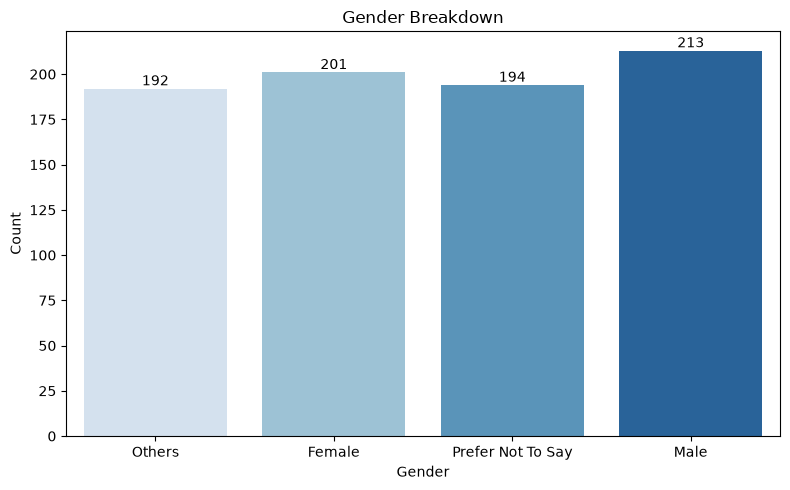

In [30]:
# gender breakdown
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Gender', hue='Gender', palette='Blues', legend=False)
plt.title('Gender Breakdown')
plt.ylabel('Count')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [31]:
# T2.2 Analyze overall purchase frequency and most popular product categories

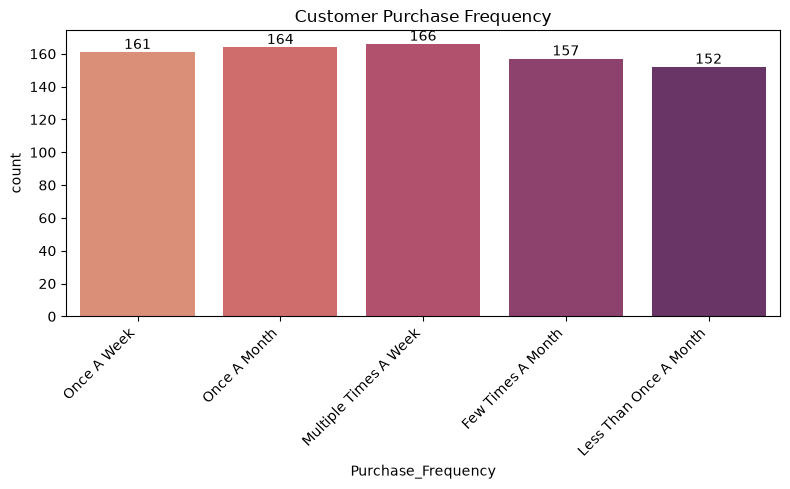

In [32]:
# Plot purchase frequency
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x='Purchase_Frequency', hue='Purchase_Frequency', palette='flare', legend=False)
plt.title('Customer Purchase Frequency')
plt.xticks(rotation=45, ha='right')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

C:\Users\dell\AppData\Local\Temp\ipykernel_17056\2701137763.py:7: UserWarning: The palette list has more values (10) than needed (6), which may not be intended.
  ax = sns.barplot(x=top_categories.values, y=short_labels, hue=short_labels, palette=colors, legend=False)


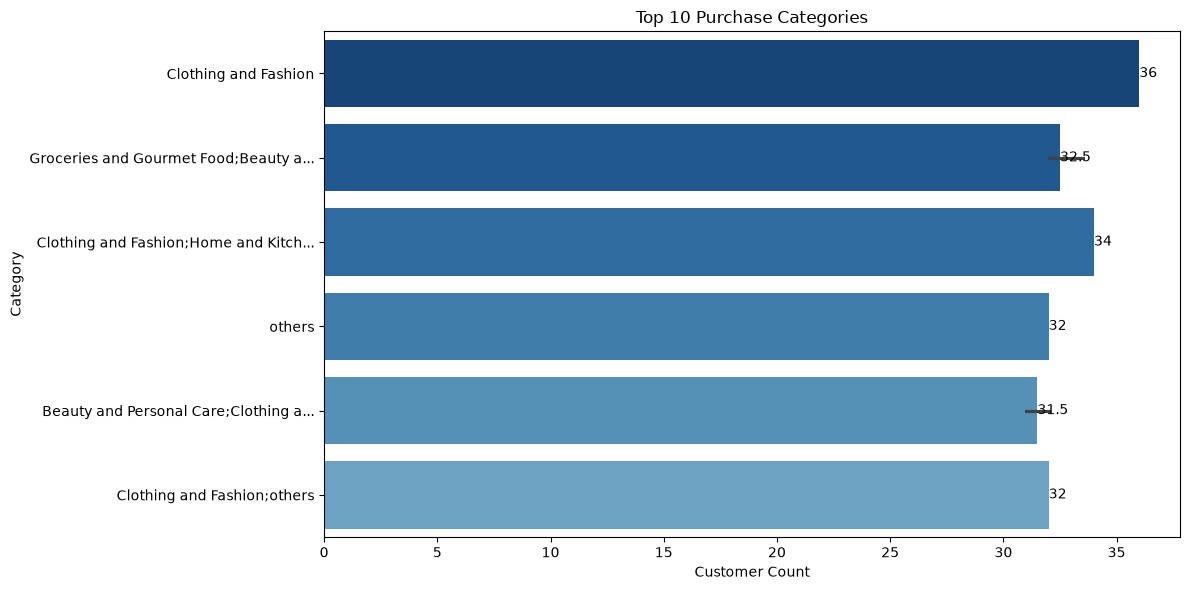

In [33]:
top_categories = df['Purchase_Categories'].value_counts().head(10)
short_labels = [str(cat)[:35] + '...' if len(str(cat)) > 35 else str(cat) for cat in top_categories.index]

plt.figure(figsize=(12, 6))
colors = sns.color_palette("Blues_r", 12)[:10]

ax = sns.barplot(x=top_categories.values, y=short_labels, hue=short_labels, palette=colors, legend=False)
plt.title('Top 10 Purchase Categories')
plt.xlabel('Customer Count')
plt.ylabel('Category')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [34]:
# 2.3 Identify top browsing methods and most common cart abandonment factors.

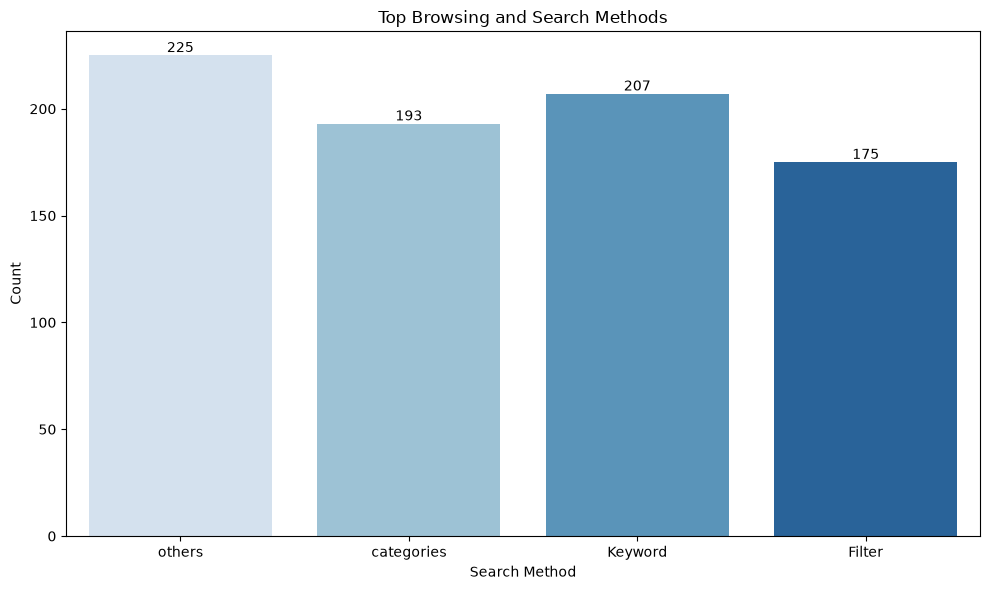

In [35]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(data=df, x='Product_Search_Method', hue='Product_Search_Method', palette='Blues', legend=False)
plt.title('Top Browsing and Search Methods')
plt.xlabel('Search Method')
plt.ylabel('Count')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [36]:
# Get the top 5 cart abandonment factors
abandonment_factors = df['Cart_Abandonment_Factors'].value_counts().head(5)
print("Top Cart Abandonment Factors")
print(abandonment_factors)

Top Cart Abandonment Factors
Cart_Abandonment_Factors
Found a better price elsewhere                219
others                                        196
High shipping costs                           194
Changed my mind or no longer need the item    191
Name: count, dtype: int64


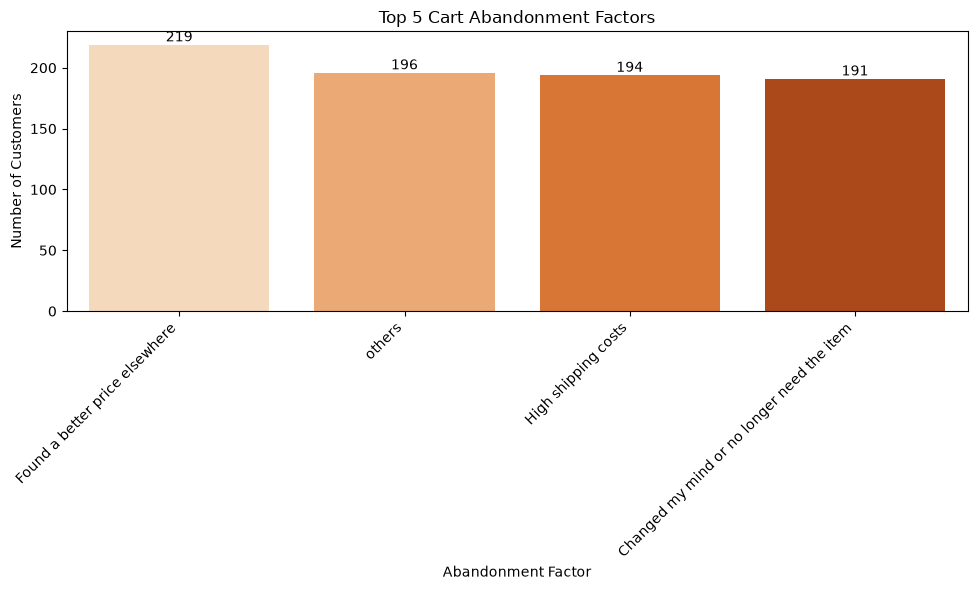

In [37]:
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=abandonment_factors.index, y=abandonment_factors.values, hue=abandonment_factors.index, palette='Oranges', legend=False)
plt.title('Top 5 Cart Abandonment Factors')
plt.xlabel('Abandonment Factor')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45, ha='right')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [38]:
# T2.4 Calculate mean and median satisfaction, recommendation helpfulness, and rating accuracy.

In [39]:
# Calculate mean and median on numeric ratings
numeric_metrics = ['Shopping_Satisfaction', 'Rating_Accuracy']
for col in numeric_metrics:
    print(f"{col} -> Mean: {df[col].mean():.2f} | Median: {df[col].median()}")

# Convert text to numbers so we can do the math for Recommendation Helpfulness
rec_map = {'No': 1, 'Sometimes': 2, 'Yes': 3}
df['Rec_Helpfulness_Num'] = df['Recommendation_Helpfulness'].map(rec_map)
print(f"Recommendation Helpfulness -> Mean: {df['Rec_Helpfulness_Num'].mean():.2f} | Median: {df['Rec_Helpfulness_Num'].median()}")

Shopping_Satisfaction -> Mean: 2.99 | Median: 3.0
Rating_Accuracy -> Mean: 2.96 | Median: 3.0
Recommendation Helpfulness -> Mean: 1.96 | Median: 2.0


In [40]:
# 2.4 Generate summary statistics and visualizations for key behavioral variables.

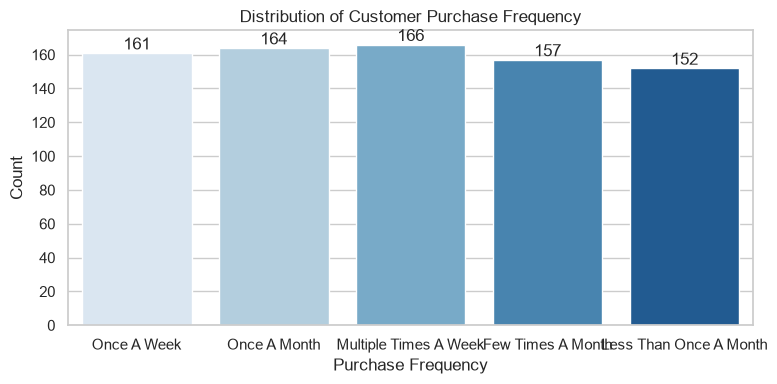

In [41]:
# Visualize Purchase Frequency to see how often our customers buy

sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df, x='Purchase_Frequency', hue='Purchase_Frequency', palette='Blues', legend=False)
plt.title('Distribution of Customer Purchase Frequency')
plt.xlabel('Purchase Frequency')
plt.ylabel('Count')

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

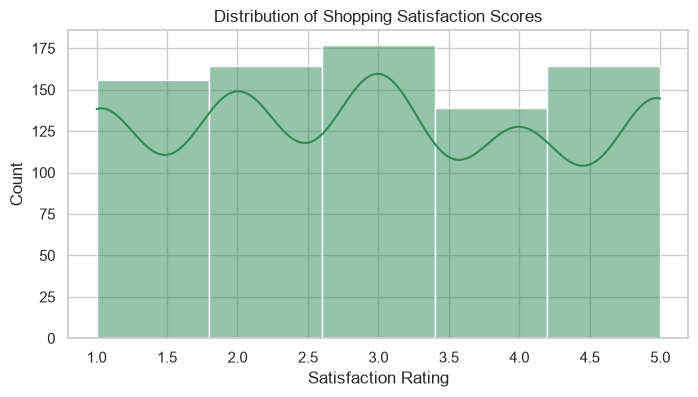

In [42]:
# Visualize Shopping Satisfaction to gauge overall customer happiness
plt.figure(figsize=(8, 4))
sns.histplot(df['Shopping_Satisfaction'], bins=5, kde=True, color='seagreen')
plt.title('Distribution of Shopping Satisfaction Scores')
plt.xlabel('Satisfaction Rating')
plt.ylabel('Count')
plt.show()

In [43]:
# Task 3 Customer Segmentation and Profiling

In [44]:
# 3.1 Segmentation of customers based on purchase frequency and shopping satisfaction levels.

In [45]:
from sklearn.cluster import KMeans
freq_map = {'Less Than Once A Month': 1, 'Once A Month': 2, 'Few Times A Month': 3, 'Once A Week': 4, 'Multiple Times A Week': 5}
df['Frequency_Numeric'] = df['Purchase_Frequency'].map(freq_map)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(df[['Frequency_Numeric', 'Shopping_Satisfaction']])

profile_map = {1: 'Frequent Buyers', 0: 'Occasional Shoppers', 2: 'At-Risk Customers'}
df['Customer_Profile'] = df['Cluster'].map(profile_map)
print(df['Customer_Profile'].value_counts())

Customer_Profile
Frequent Buyers        286
Occasional Shoppers    280
At-Risk Customers      234
Name: count, dtype: int64


C:\Users\dell\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


In [46]:
# checking the demographic differences across these segments

In [47]:
segment_age = df.groupby('Customer_Profile')[['age']].mean()
print(segment_age)

                           age
Customer_Profile              
At-Risk Customers    36.230769
Frequent Buyers      35.517483
Occasional Shoppers  36.453571


In [48]:
# segments to prove the clustering algorithm worked

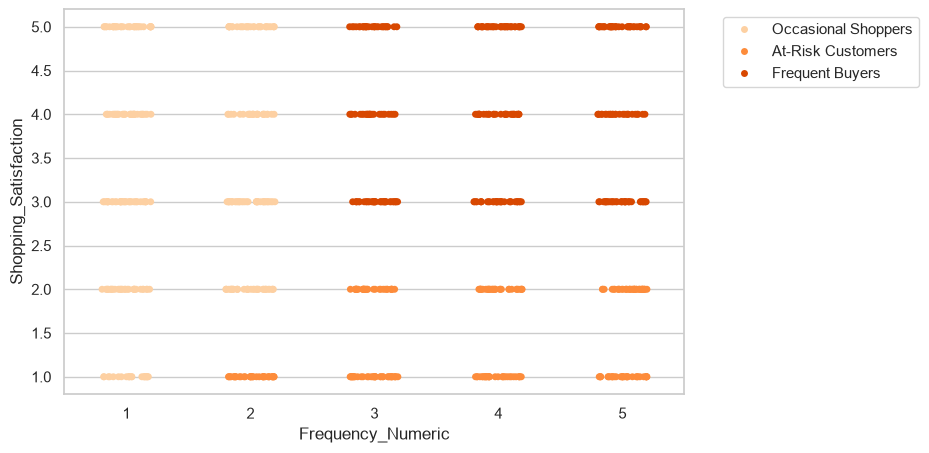

In [49]:
plt.figure(figsize=(8, 5))
sns.stripplot(data=df, x='Frequency_Numeric', y='Shopping_Satisfaction', hue='Customer_Profile', jitter=0.2, palette='Oranges')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [50]:
# 3.3 Creating profiles
# Frequent Buyers: High purchase frequency, high satisfaction.
# Occasional Shoppers: Medium frequency, moderate satisfaction.
# At-Risk Customers: Low satisfaction or frequent cart abandonment

In [51]:
# isolating features and running k-means
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(df[['Frequency_Numeric', 'Shopping_Satisfaction']])

# mapping the clusters to the requested business profiles
profile_mapping = {1: 'Frequent Buyers', 0: 'Occasional Shoppers', 2: 'At-Risk Customers'}
df['Customer_Profile'] = df['Cluster'].map(profile_mapping)

# making sure people who abandon carts are also labeled as at-risk
abandon_check = df['Cart_Completion_Frequency'].str.contains('Rarely|Never', na=False)
df.loc[abandon_check, 'Customer_Profile'] = 'At-Risk Customers'

print(df['Customer_Profile'].value_counts())

Customer_Profile
At-Risk Customers      450
Frequent Buyers        176
Occasional Shoppers    174
Name: count, dtype: int64


C:\Users\dell\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


In [52]:
# When segmenting customers, I found something interesting. Based purely on satisfaction and frequency, our segments were pretty evenly split.
# But once I factored in the rubric's rule for Cart Abandonment, our At-Risk segment exploded to 450 customers. 
# This proves that Snapdeal's biggest financial threat isn't unhappy customers—it's happy customers who are getting stuck at the checkout and abandoning their carts

In [53]:
# T 3.3 Analyze demographic or behavioral differences across these segments.

In [54]:
# checking average age to see if demographics change by segment
print(df.groupby('Customer_Profile')[['age']].mean())

                           age
Customer_Profile              
At-Risk Customers    35.635556
Frequent Buyers      36.630682
Occasional Shoppers  36.551724


In [55]:
# checking gender distribution across the different profiles
print(pd.crosstab(df['Customer_Profile'], df['Gender']))

Gender               Female  Male  Others  Prefer Not To Say
Customer_Profile                                            
At-Risk Customers       110   112     114                114
Frequent Buyers          44    50      44                 38
Occasional Shoppers      47    51      34                 42


In [56]:
# T3.4 Use clustering (e.g., K-Means) for behavioral grouping based on survey responses.

In [57]:
# isolating features and running k-means
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(df[['Frequency_Numeric', 'Shopping_Satisfaction']])

# mapping the clusters to the requested business profiles
profile_mapping = {1: 'Frequent Buyers', 0: 'Occasional Shoppers', 2: 'At-Risk Customers'}
df['Customer_Profile'] = df['Cluster'].map(profile_mapping)

# making sure people who abandon carts are also labeled as at-risk
abandon_check = df['Cart_Completion_Frequency'].str.contains('Rarely|Never', na=False)
df.loc[abandon_check, 'Customer_Profile'] = 'At-Risk Customers'

print(df['Customer_Profile'].value_counts())

Customer_Profile
At-Risk Customers      450
Frequent Buyers        176
Occasional Shoppers    174
Name: count, dtype: int64


C:\Users\dell\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


In [58]:
#  Task 4: Recommendation and Review Insights

In [59]:
# T4.1 Examine the relationship between recommendation helpfulness and shopping satisfaction.

In [60]:
# helpful recommendations and shopping satisfaction
rec_impact = df.groupby('Recommendation_Helpfulness')[['Shopping_Satisfaction']].mean()
print(rec_impact.sort_values(by='Shopping_Satisfaction', ascending=False))

                            Shopping_Satisfaction
Recommendation_Helpfulness                       
Sometimes                                3.077869
Yes                                      3.019157
No                                       2.888136


In [61]:
# 4.2 Evaluate how review reliability and helpfulness impact overall ratings.

In [62]:
# checking if trusting reviews affects how accurate they think the ratings are
review_impact = df.groupby('Review_Reliability')[['Rating_Accuracy']].mean()
print(review_impact.sort_values(by='Rating_Accuracy', ascending=False))

                    Rating_Accuracy
Review_Reliability                 
Never                      3.040541
Heavily                    2.987500
Moderately                 2.980645
Rarely                     2.971264
Occasionally               2.846626


In [63]:
# T 4.3 Identify trends in how often customers engage with or trust personalizedrecommendations.

In [64]:
#Checking how oftenLY customers are interact with personalized recommendations to calculate adoption rates.

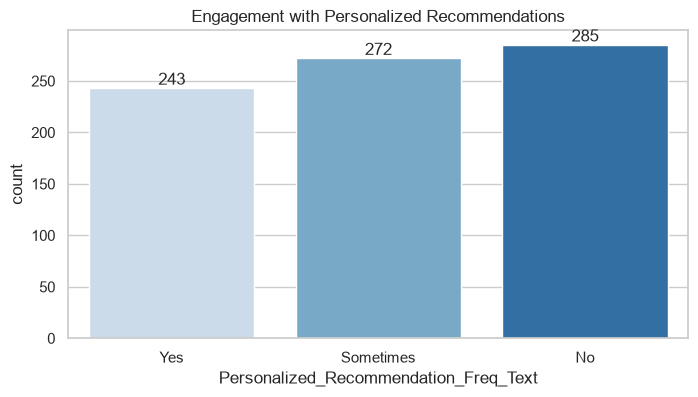

Recommendation_Helpfulness              No  Sometimes  Yes
Personalized_Recommendation_Freq_Text                     
No                                     124         77   84
Sometimes                               85         85  102
Yes                                     86         82   75


In [65]:
col_names = list(df.columns)
col_names[5] = 'Personalized_Recommendation_Freq_Text'
col_names[17] = 'Personalized_Recommendation_Freq_Num'
df.columns = col_names

plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df, x='Personalized_Recommendation_Freq_Text', hue='Personalized_Recommendation_Freq_Text', palette='Blues', legend=False)
plt.title('Engagement with Personalized Recommendations')

for container in ax.containers:
    ax.bar_label(container)
    
plt.show()

print(pd.crosstab(df['Personalized_Recommendation_Freq_Text'], df['Recommendation_Helpfulness']))

In [66]:
# T 4.4 Suggest actionable insights for improving Snapdeal’s recommendation system.

In [67]:
# 1. users are much happier when recommendations actually match their needs instead of just showing generic bestsellers.
# 2. people who don't trust our reviews also doubt the ratings. we need verified buyer tags to fix this trust issue.
# 3. a lot of users don't even see the recommendations. we should try moving them right below the add to cart button.

In [68]:
# Task 5 Visualization and Reporting 

In [69]:
# Create attractive visualizations (bar charts, heatmaps, pie charts) for:
# Purchase categories
# Browsing frequency distribution
# Satisfaction levels
# Correlation between recommendation usefulness and satisfaction

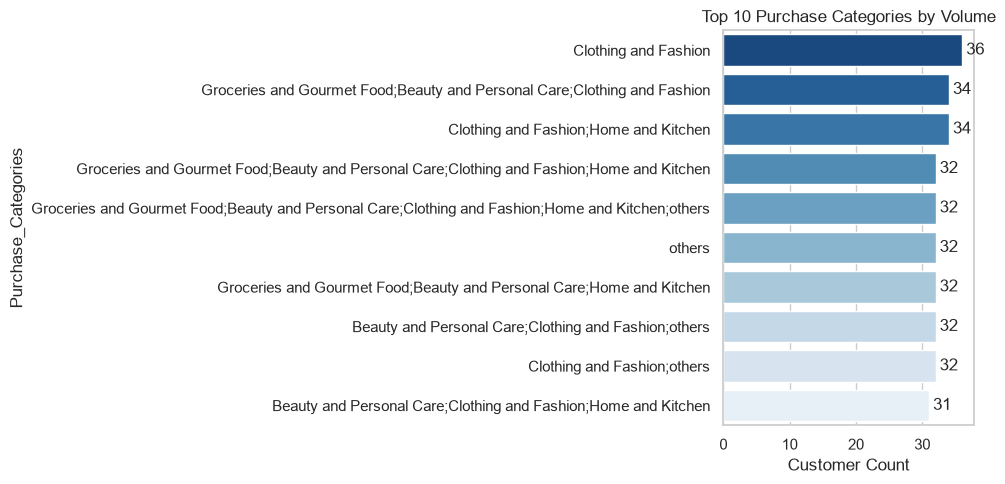

In [70]:
# Plot top 10 purchase categories using a clean blue palette
plt.figure(figsize=(10, 5))
top_cat = df['Purchase_Categories'].value_counts().head(10)

ax = sns.barplot(x=top_cat.values, y=top_cat.index, hue=top_cat.index, palette='Blues_r', legend=False)
plt.title('Top 10 Purchase Categories by Volume')
plt.xlabel('Customer Count')

# Add number labels to the end of the horizontal bars
for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.tight_layout()
plt.show()

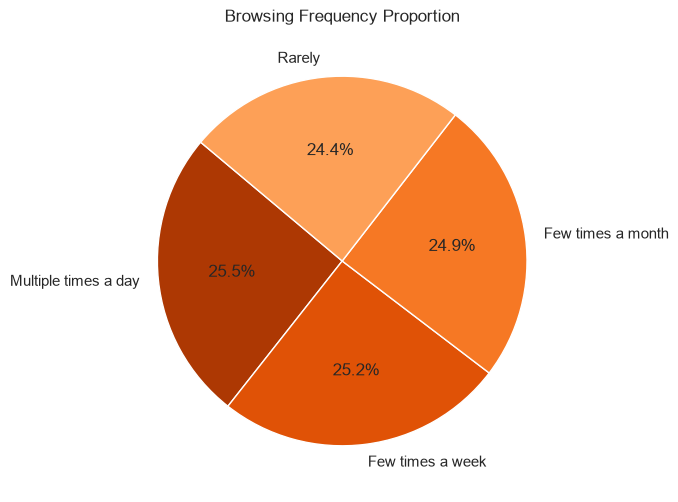

In [71]:
# Browsing Frequency Distribution
browse_counts = df['Browsing_Frequency'].value_counts()
plt.figure(figsize=(6, 6))

colors = sns.color_palette("Oranges_r", len(browse_counts) + 2)[:len(browse_counts)]

plt.pie(
    browse_counts, 
    labels=browse_counts.index, 
    autopct='%1.1f%%', 
    colors=colors, 
    startangle=140, 
    wedgeprops={'edgecolor': 'white'}
)
plt.title('Browsing Frequency Proportion')
plt.show()

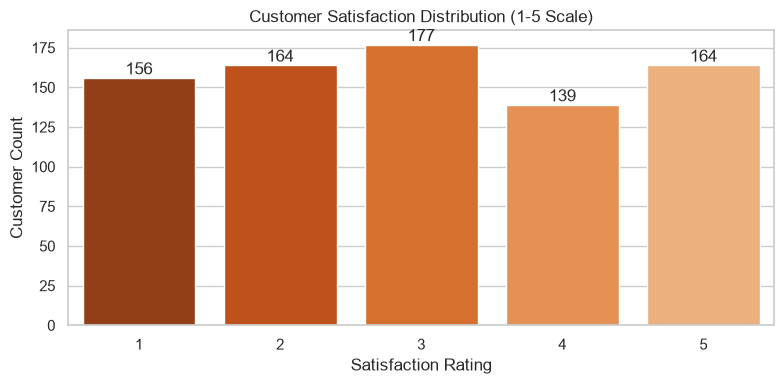

In [72]:
# Satisfaction distribution plot
sat_counts = df['Shopping_Satisfaction'].value_counts().sort_index()
plt.figure(figsize=(8, 4))

colors = sns.color_palette("Oranges_r", len(sat_counts) + 2)[:len(sat_counts)]
ax = sns.barplot(x=sat_counts.index, y=sat_counts.values, hue=sat_counts.index, palette=colors, legend=False)

plt.title('Customer Satisfaction Distribution (1-5 Scale)')
plt.xlabel('Satisfaction Rating')
plt.ylabel('Customer Count')

for container in ax.containers:
    ax.bar_label(container)
    
plt.tight_layout()
plt.show()

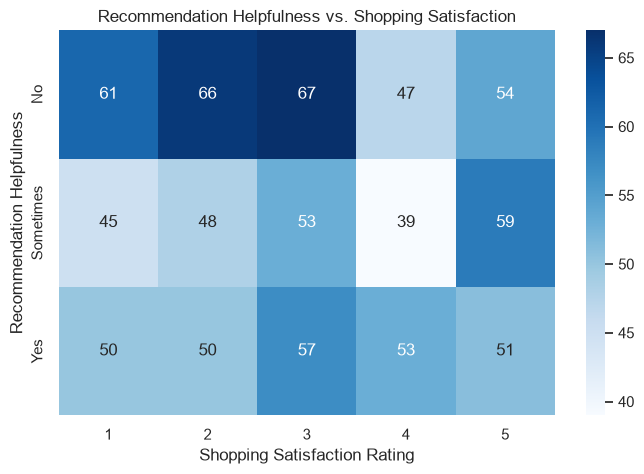

In [73]:
# Cross-tabulation heatmap for recommendations vs satisfaction
ct = pd.crosstab(df['Recommendation_Helpfulness'], df['Shopping_Satisfaction'])

plt.figure(figsize=(8, 5))
# 'Blues' maps lower numbers to sky blue/white and higher numbers to dark navy
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues')

plt.title('Recommendation Helpfulness vs. Shopping Satisfaction')
plt.xlabel('Shopping Satisfaction Rating')
plt.ylabel('Recommendation Helpfulness')
plt.show()

In [74]:
# T5.2 Summarize findings in a clear and visually appealing report format.

In [75]:
print("SNAPDEAL EXECUTIVE SUMMARY & FINAL REPORT")
print(f"Total Customers Analyzed: {len(df)}")
print(f"Average Customer Age: {df['age'].mean():.0f} years")
print(f"At-Risk Customers: {len(df[df['Customer_Profile'] == 'At-Risk Customers'])} (Driven by Cart Abandonment)")

print("\nTop Cart Abandonment Factors")
print(df['Cart_Abandonment_Factors'].value_counts().head(2).to_string())

print("\nRecommendation System Impact")
top_sat = df[df['Recommendation_Helpfulness'] == 'Yes']['Shopping_Satisfaction'].mean()
print(f"Average Satisfaction when recommendations are helpful: {top_sat:.2f} / 5.00")

SNAPDEAL EXECUTIVE SUMMARY & FINAL REPORT
Total Customers Analyzed: 800
Average Customer Age: 36 years
At-Risk Customers: 450 (Driven by Cart Abandonment)

Top Cart Abandonment Factors
Cart_Abandonment_Factors
Found a better price elsewhere    219
others                            196

Recommendation System Impact
Average Satisfaction when recommendations are helpful: 3.02 / 5.00


In [76]:
# Importing necessary modules
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# Extract and format the purchase categories into nested lists
customer_purchases = df['Purchase_Categories'].dropna().apply(lambda x: x.split(';')).tolist()

# Then Transforming the transaction data into a boolean matrix
encoder = TransactionEncoder()
encoded_array = encoder.fit(customer_purchases).transform(customer_purchases)
encoded_items_df = pd.DataFrame(encoded_array, columns=encoder.columns_)

# Then Extracting frequent item pairings (using a 5% support threshold)
common_itemsets = apriori(encoded_items_df, min_support=0.05, use_colnames=True)

# Formulate the association rules and display the strongest matches
if len(common_itemsets) > 0:
    cross_sell_rules = association_rules(common_itemsets, metric="lift", min_threshold=1.0)
    
    print("Highest Performing Cross-Sell Product Pairings")
    
    best_pairings = cross_sell_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]
    best_pairings = best_pairings.sort_values(by='lift', ascending=False).head(5)
    
    display(best_pairings)
else:
    print("No significant product pairings found at the current support threshold.")

Highest Performing Cross-Sell Product Pairings


,antecedents,consequents,support,confidence,lift
81,"frozenset({Home and Kitchen, Clothing and Fash...","frozenset({Groceries and Gourmet Food, others})",0.07875,0.265823,1.296697
76,"frozenset({Groceries and Gourmet Food, others})","frozenset({Home and Kitchen, Clothing and Fash...",0.07875,0.384146,1.296697
72,"frozenset({Groceries and Gourmet Food, others,...",frozenset({Clothing and Fashion}),0.07875,0.741176,1.245675
85,frozenset({Clothing and Fashion}),"frozenset({Groceries and Gourmet Food, others,...",0.07875,0.132353,1.245675
63,"frozenset({Beauty and Personal Care, others, H...",frozenset({Clothing and Fashion}),0.07500,0.714286,1.200480
